# Melbourne EV Charging Demand: Demand Forecasting, Peak-Load Classification and Station Clustering

**Dataset:** CHARGED hourly Melbourne (MEL) files, April to September 2023, 63 stations.

**Required models (problem statement):** Task 1 Linear Regression, Task 2 Logistic Regression, Task 3 K-Means.
Additional models (Ridge, Lasso, tree ensembles, SVM, DBSCAN, GMM) are used only as comparisons.

**Methodological focus:** prediction-time feature availability, chronological validation, an untouched test period, naive baselines, and station-level error/risk analysis.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, RocCurveDisplay
)
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
DATA_FOLDER = Path(r"C:\Users\LENOVO\Downloads\Hourly\MEL")
OUTPUT_FOLDER = Path.cwd() / "melbourne_project_outputs"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
FILES = ["volume.csv", "duration.csv", "e_price.csv", "s_price.csv", "weather.csv",
         "stations.csv", "piles.csv", "distance.csv", "inf.csv", "info.csv", "poi.csv"]
missing_files = [name for name in FILES if not (DATA_FOLDER / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing CSV files under {DATA_FOLDER}: {missing_files}")

## 1. Load and inspect every supplied file

All files are loaded and summarized before selecting inputs. We display dimensions, column names, data types, missing-value counts, duplicate counts, and the first five rows. Some files are large; the full files are loaded, but only five sample rows are displayed.

In [2]:
raw = {Path(name).stem: pd.read_csv(DATA_FOLDER / name) for name in FILES}
inspection_rows = []
for name, frame in raw.items():
    inspection_rows.append({
        "file": f"{name}.csv", "rows": len(frame), "columns": len(frame.columns),
        "column_names": ", ".join(map(str, frame.columns)),
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_rows": int(frame.duplicated().sum())
    })
    cols = frame.columns.tolist()
    print(f"\n### {name}.csv - {frame.shape}")
    print("Columns:", cols if len(cols) <= 20 else f"{cols[:6]} ... ({len(cols)} columns in total)")
    print("Missing cells:", int(frame.isna().sum().sum()), "| duplicate rows:", int(frame.duplicated().sum()))
    display(frame.iloc[:5, :8])
inspection = pd.DataFrame(inspection_rows)
display(inspection[["file", "rows", "columns", "missing_cells", "duplicate_rows"]])
inspection.to_csv(OUTPUT_FOLDER / "file_inspection.csv", index=False)


### volume.csv - (4392, 64)
Columns: ['Unnamed: 0', '0', '1', '10', '11', '12'] ... (64 columns in total)
Missing cells: 0 | duplicate rows: 0


,Unnamed: 0,0,1,10,11,12,13,14
0,2023-04-01 00:00:00,0.0,0.0,0.000000,0.0,23.794135,0.0,44.0
1,2023-04-01 01:00:00,0.0,0.0,0.000000,0.0,23.870852,0.0,44.0
2,2023-04-01 02:00:00,0.0,0.0,0.000000,0.0,23.947569,0.0,44.0
3,2023-04-01 03:00:00,0.0,0.0,3.666667,0.0,24.024286,0.0,44.0
4,2023-04-01 04:00:00,0.0,0.0,44.000000,0.0,24.101003,0.0,44.0



### duration.csv - (4392, 64)
Columns: ['Unnamed: 0', '0', '1', '10', '11', '12'] ... (64 columns in total)
Missing cells: 0 | duplicate rows: 0


,Unnamed: 0,0,1,10,11,12,13,14
0,2023-04-01 00:00:00,0.0,0.0,0.000000,0.0,1.381328,0.0,2.0
1,2023-04-01 01:00:00,0.0,0.0,0.000000,0.0,1.389536,0.0,2.0
2,2023-04-01 02:00:00,0.0,0.0,0.000000,0.0,1.397744,0.0,2.0
3,2023-04-01 03:00:00,0.0,0.0,0.166667,0.0,1.405952,0.0,2.0
4,2023-04-01 04:00:00,0.0,0.0,2.000000,0.0,1.414160,0.0,2.0



### e_price.csv - (4392, 64)
Columns: ['time', '0', '1', '10', '11', '12'] ... (64 columns in total)
Missing cells: 0 | duplicate rows: 0


,time,0,1,10,11,12,13,14
0,2023-04-01 00:00:00,0.0,0.3,0.0,0.0,0.0,0.0,0.0
1,2023-04-01 01:00:00,0.0,0.3,0.0,0.0,0.0,0.0,0.0
2,2023-04-01 02:00:00,0.0,0.3,0.0,0.0,0.0,0.0,0.0
3,2023-04-01 03:00:00,0.0,0.3,0.0,0.0,0.0,0.0,0.0
4,2023-04-01 04:00:00,0.0,0.3,0.0,0.0,0.0,0.0,0.0


... (13 outputs left out)

,city,country,abbreviation,total_piles,total_stations,DBSCAN_eps,total_duration,total_volume
0,Melbourne,Australia,MEL,64,63,32.957544,683027.393689,2.726185e+07



### poi.csv - (617806, 4)
Columns: ['Unnamed: 0', 'type', 'longitude', 'latitude']
Missing cells: 0 | duplicate rows: 0


,Unnamed: 0,type,longitude,latitude
0,0,hospital,145.145572,-37.884379
1,1,place_of_worship,145.146413,-37.884698
2,2,toilets,145.164118,-37.880202
3,3,other,145.127798,-38.070649
4,4,other,145.001088,-37.797160


,file,rows,columns,missing_cells,duplicate_rows
0,volume.csv,4392,64,0,0
1,duration.csv,4392,64,0,0
2,e_price.csv,4392,64,0,0
3,s_price.csv,4392,64,0,0
4,weather.csv,4392,19,4147,0
5,stations.csv,63,9,0,0
6,piles.csv,64,7,0,0
7,distance.csv,63,64,0,0
8,inf.csv,63,7,0,0
9,info.csv,1,9,0,0


## 2. Decide which files support Tasks 1 and 2

The target is the hourly station-level matrix in `volume.csv`. Verified time-varying station-level predictors are `duration.csv`, `e_price.csv`, and `s_price.csv`; city-wide weather joins by timestamp. `stations.csv` adds stable station location and infrastructure attributes after station IDs are checked.

The remaining files are inspected but not forced into the model: `piles.csv` is charger-level (64 records versus 63 station targets), `distance.csv` is a pairwise 63×63 matrix, `poi.csv` is a large point dataset requiring a spatial aggregation rule, `inf.csv` duplicates/augments station geometry but is not needed when using `stations.csv`, and `info.csv` is one city-level summary row. This avoids unsupported many-to-many joins and static full-period outcome summaries that could leak information.

In [3]:
def normalize_time_frame(frame, label):
    out = frame.copy()
    first = out.columns[0]
    out = out.rename(columns={first: "timestamp"})
    out["timestamp"] = pd.to_datetime(out["timestamp"], errors="coerce")
    if out["timestamp"].isna().any():
        raise ValueError(f"{label}: could not parse every timestamp")
    if out["timestamp"].duplicated().any():
        raise ValueError(f"{label}: duplicate timestamps")
    return out

wide = {name: normalize_time_frame(raw[name], name)
        for name in ["volume", "duration", "e_price", "s_price", "weather"]}
volume_wide = wide["volume"]
station_ids = [str(c) for c in volume_wide.columns if c != "timestamp"]
print("Volume shape:", volume_wide.shape, "| station columns:", len(station_ids))
print("Date range:", volume_wide.timestamp.min(), "to", volume_wide.timestamp.max())
print("Unique timestamp intervals:\n", volume_wide.timestamp.sort_values().diff().value_counts().head())
for name, frame in wide.items():
    print(f"{name}: rows={len(frame)}, exact volume timestamp alignment={frame.timestamp.equals(volume_wide.timestamp)}")

stations = raw["stations"].copy()
stations["station_id"] = stations["station_id"].astype(str)
print("Station IDs in volume:", len(set(station_ids)))
print("Station IDs in stations.csv:", stations.station_id.nunique())
print("Volume IDs missing from stations.csv:", sorted(set(station_ids)-set(stations.station_id)))
print("Metadata IDs missing from volume:", sorted(set(stations.station_id)-set(station_ids)))
print("Station metadata duplicate IDs:", int(stations.station_id.duplicated().sum()))
print("Other structures:", {
    "piles rows": len(raw["piles"]), "distance matrix": raw["distance"].shape,
    "inf rows": len(raw["inf"]), "poi rows": len(raw["poi"]), "info rows": len(raw["info"])
})

Volume shape: (4392, 64) | station columns: 63
Date range: 2023-04-01 00:00:00 to 2023-09-30 23:00:00
Unique timestamp intervals:
 timestamp
0 days 01:00:00    4391
Name: count, dtype: int64
volume: rows=4392, exact volume timestamp alignment=True
duration: rows=4392, exact volume timestamp alignment=True
e_price: rows=4392, exact volume timestamp alignment=True
s_price: rows=4392, exact volume timestamp alignment=True
weather: rows=4392, exact volume timestamp alignment=True
Station IDs in volume: 63
Station IDs in stations.csv: 63
Volume IDs missing from stations.csv: []
Metadata IDs missing from volume: []
Station metadata duplicate IDs: 0
Other structures: {'piles rows': 64, 'distance matrix': (63, 64), 'inf rows': 63, 'poi rows': 617806, 'info rows': 1}


## 3. Prepare and join the hourly station data

Each wide matrix is reshaped to `(timestamp, station_id, value)`. The joins are one-to-one on timestamp and station ID; weather joins many-to-one on timestamp; station attributes join many-to-one on station ID. The code checks timestamp and station keys before merging. Recorded zeros are retained as valid observations. Missing predictor values are handled later inside train-fitted model pipelines.

In [4]:
def melt_station_matrix(frame, value_name):
    station_columns = [c for c in frame.columns if c != "timestamp"]
    long = frame.melt(id_vars="timestamp", value_vars=station_columns,
                      var_name="station_id", value_name=value_name)
    long["station_id"] = long["station_id"].astype(str)
    long[value_name] = pd.to_numeric(long[value_name], errors="coerce")
    return long

long_data = melt_station_matrix(wide["volume"], "volume")
for name in ["duration", "e_price", "s_price"]:
    part = melt_station_matrix(wide[name], name)
    long_data = long_data.merge(part, on=["timestamp", "station_id"], how="inner", validate="one_to_one")
weather = wide["weather"].copy()
long_data = long_data.merge(weather, on="timestamp", how="left", validate="many_to_one")
station_meta_cols = [c for c in ["station_id", "longitude", "latitude", "pile_num", "perimeter", "area"] if c in stations]
long_data = long_data.merge(stations[station_meta_cols], on="station_id", how="left", validate="many_to_one")
long_data = long_data.sort_values(["station_id", "timestamp"]).reset_index(drop=True)
print("Joined table:", long_data.shape)
print("Duplicate timestamp-station keys:", int(long_data.duplicated(["timestamp", "station_id"]).sum()))
print("Missing target:", int(long_data.volume.isna().sum()), "| negative target:", int((long_data.volume < 0).sum()))
print("Zero target rows:", int((long_data.volume == 0).sum()), "of", len(long_data))
print("Missing values by column:\n", long_data.isna().sum().sort_values(ascending=False).head(15))
display(long_data.head())

Joined table: (276696, 29)
Duplicate timestamp-station keys: 0
Missing target: 0 | negative target: 0
Zero target rows: 82397 of 276696
Missing values by column:
 preciptype    261261
station_id         0
volume             0
duration           0
timestamp          0
s_price            0
temp               0
feelslike          0
humidity           0
dew                0
precip             0
snow               0
e_price            0
snowdepth          0
windgust           0
dtype: int64


,timestamp,station_id,volume,duration,e_price,s_price,temp,feelslike,humidity,dew,...,cloudcover,solarradiation,solarenergy,uvindex,conditions,longitude,latitude,pile_num,perimeter,area
0,2023-04-01 00:00:00,0,0.0,0.0,0.0,0.0,13.4,13.4,70.29,8.1,...,29.2,0.0,0.0,0,2,145.111076,-37.689403,1,235.757988,4330.089582
1,2023-04-01 01:00:00,0,0.0,0.0,0.0,0.0,12.8,12.8,71.70,7.8,...,51.2,0.0,0.0,0,2,145.111076,-37.689403,1,235.757988,4330.089582
2,2023-04-01 02:00:00,0,0.0,0.0,0.0,0.0,12.4,12.4,77.05,8.5,...,48.7,0.0,0.0,0,2,145.111076,-37.689403,1,235.757988,4330.089582
3,2023-04-01 03:00:00,0,0.0,0.0,0.0,0.0,12.0,12.0,85.88,9.7,...,98.0,0.0,0.0,0,5,145.111076,-37.689403,1,235.757988,4330.089582
4,2023-04-01 04:00:00,0,0.0,0.0,0.0,0.0,11.6,11.6,83.48,8.9,...,70.7,0.0,0.0,0,2,145.111076,-37.689403,1,235.757988,4330.089582


## 4. Feature engineering and exploratory analysis

Calendar fields and cyclical encodings describe time-of-day and weekday patterns. Station-specific demand lags use only earlier observations: 1 hour, 24 hours, and 168 hours (one week). This setup evaluates one-step-ahead predictions, where the latest observed demand is available. Missing early-history lag rows are removed because the feature values do not yet exist; zero demand itself is not removed.

Lag missing counts:
 volume_lag_1         63
volume_lag_24      1512
volume_lag_168    10584
dtype: int64


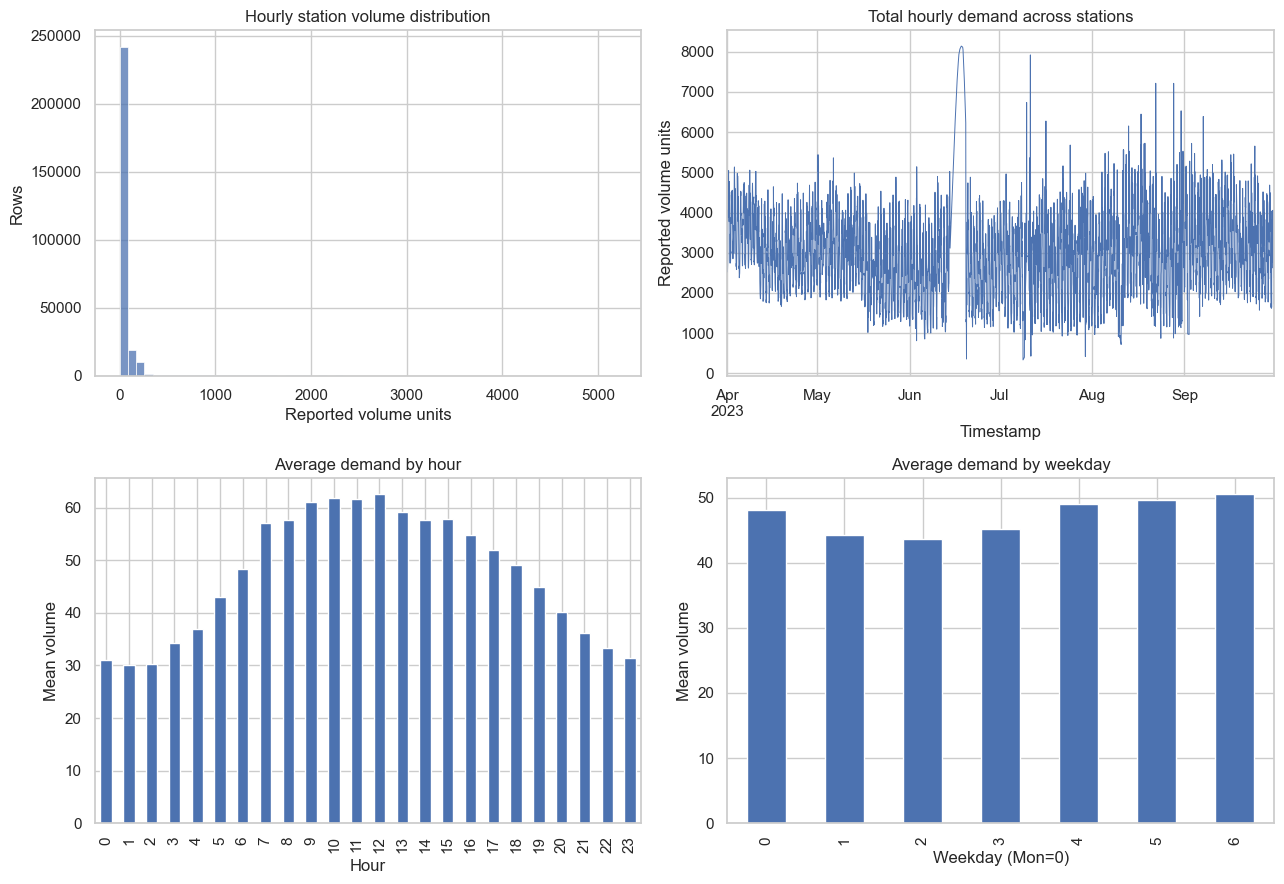

In [5]:
long_data["hour"] = long_data.timestamp.dt.hour
long_data["day_of_week"] = long_data.timestamp.dt.dayofweek
long_data["month"] = long_data.timestamp.dt.month
long_data["day_of_month"] = long_data.timestamp.dt.day
long_data["is_weekend"] = (long_data.day_of_week >= 5).astype(int)
long_data["hour_sin"] = np.sin(2*np.pi*long_data.hour/24)
long_data["hour_cos"] = np.cos(2*np.pi*long_data.hour/24)
long_data["day_sin"] = np.sin(2*np.pi*long_data.day_of_week/7)
long_data["day_cos"] = np.cos(2*np.pi*long_data.day_of_week/7)
long_data["volume_lag_1"] = long_data.groupby("station_id").volume.shift(1)
long_data["volume_lag_24"] = long_data.groupby("station_id").volume.shift(24)
long_data["volume_lag_168"] = long_data.groupby("station_id").volume.shift(168)
print("Lag missing counts:\n", long_data[["volume_lag_1","volume_lag_24","volume_lag_168"]].isna().sum())

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(long_data.volume.dropna(), bins=60, ax=axes[0,0]); axes[0,0].set(title="Hourly station volume distribution", xlabel="Reported volume units", ylabel="Rows")
long_data.groupby("timestamp").volume.sum().plot(ax=axes[0,1], linewidth=.7); axes[0,1].set(title="Total hourly demand across stations", xlabel="Timestamp", ylabel="Reported volume units")
long_data.groupby("hour").volume.mean().plot(kind="bar", ax=axes[1,0]); axes[1,0].set(title="Average demand by hour", xlabel="Hour", ylabel="Mean volume")
long_data.groupby("day_of_week").volume.mean().plot(kind="bar", ax=axes[1,1]); axes[1,1].set(title="Average demand by weekday", xlabel="Weekday (Mon=0)", ylabel="Mean volume")
fig.tight_layout(); fig.savefig(OUTPUT_FOLDER/"task1_eda.png", dpi=150); plt.show()

No outlier rows are deleted. The source does not state the unit of the Melbourne wide `volume.csv` values, so plots and metrics refer to reported volume units. `duration` is kept as supplied; its unit should be confirmed from the dataset documentation before interpretation.

## 5. Chronological train / validation / test split

Unique timestamps are sorted and divided into approximately 70% train, 15% validation and 15% test; all stations at the same timestamp stay together. The test period is held back from model selection. Lag features are built before splitting using only shifted past values, so a validation or test row can use earlier observed demand but never its own or a later target.

In [6]:
model_data = long_data.dropna(subset=["volume", "volume_lag_1", "volume_lag_24", "volume_lag_168"]).copy()
unique_times = np.sort(model_data.timestamp.unique())
train_end = int(len(unique_times)*0.70)
valid_end = int(len(unique_times)*0.85)
train_times, valid_times, test_times = unique_times[:train_end], unique_times[train_end:valid_end], unique_times[valid_end:]
train = model_data[model_data.timestamp.isin(train_times)].copy()
valid = model_data[model_data.timestamp.isin(valid_times)].copy()
test = model_data[model_data.timestamp.isin(test_times)].copy()
train_valid = pd.concat([train, valid], ignore_index=True)
print("Train:", train.timestamp.min(), "to", train.timestamp.max(), "rows", len(train))
print("Validation:", valid.timestamp.min(), "to", valid.timestamp.max(), "rows", len(valid))
print("Test:", test.timestamp.min(), "to", test.timestamp.max(), "rows", len(test))
assert train.timestamp.max() < valid.timestamp.min() < test.timestamp.min()

Train: 2023-04-08 00:00:00 to 2023-08-09 03:00:00 rows 186228
Validation: 2023-08-09 04:00:00 to 2023-09-04 13:00:00 rows 39942
Test: 2023-09-04 14:00:00 to 2023-09-30 23:00:00 rows 39942


### Feature relationships (exploratory only)

Correlation of numeric columns with same-hour `volume`. Same-hour `duration` and `e_price` correlate with demand but are **not available when a forecast is issued**, so they are not model inputs. Constant columns (for example `s_price`, `snow`, `snowdepth`) are excluded because their correlation is undefined.

In [7]:
corr_source = model_data.select_dtypes(include=np.number)
constant_columns = [c for c in corr_source.columns if corr_source[c].nunique() <= 1]
print("Constant columns excluded:", constant_columns)
volume_corr = corr_source.drop(columns=constant_columns).corr()["volume"].drop("volume")
volume_corr = volume_corr.reindex(volume_corr.abs().sort_values(ascending=False).index)
display(volume_corr.to_frame(name="Correlation with volume").round(3))

Constant columns excluded: ['s_price', 'snow', 'snowdepth']


,Correlation with volume
volume_lag_1,0.885
volume_lag_24,0.824
volume_lag_168,0.736
duration,0.453
e_price,0.272
longitude,-0.189
latitude,0.107
hour_cos,-0.072
humidity,-0.031
windspeed,0.030


# Task 1 - EV charging demand forecasting (Linear Regression)

**Prediction setup:** predict station demand at hour *t* after observing station history through hour *t-1* (rolling one-step-ahead).

**Inputs used**
- station demand observed 1, 24 and 168 hours earlier;
- calendar information known in advance (hour, weekday, weekend, cyclical encodings);
- stable station metadata (station identity, location, number of piles, perimeter, area).

**Inputs deliberately excluded**
- same-hour `duration`: it is measured during the charging period and is not known when the forecast is issued;
- same-hour weather and prices: this notebook does not establish that forecast weather or future prices are available at prediction time;
- `month` and `day_of_month`: the data cover each month only once, so the test period (September) contains a month value that never appears in training. A linear model would extrapolate it and a tree model would treat it as an unseen trend. `day_of_month` has no physical link to demand.

This is a **rolling one-step-ahead** experiment: after each hour is observed, its demand may be used to forecast the next hour. It is not a 24-hour-ahead forecast.

In [8]:
target = "volume"

forecast_features = [
    "volume_lag_1", "volume_lag_24", "volume_lag_168",
    "hour", "day_of_week", "is_weekend",
    "hour_sin", "hour_cos", "day_sin", "day_cos",
    "station_id", "longitude", "latitude", "pile_num", "perimeter", "area"
]
forecast_features = [c for c in forecast_features if c in model_data.columns]

X_train = train[forecast_features].copy()
y_train = train[target].copy()
X_valid = valid[forecast_features].copy()
y_valid = valid[target].copy()
X_test = test[forecast_features].copy()
y_test = test[target].copy()

cat_features = [c for c in forecast_features if not pd.api.types.is_numeric_dtype(X_train[c].dtype)]
num_features = [c for c in forecast_features if c not in cat_features]

def make_preprocessor():
    blocks = []
    if num_features:
        blocks.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", StandardScaler())
            ]),
            num_features
        ))
    if cat_features:
        blocks.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            cat_features
        ))
    return ColumnTransformer(blocks, remainder="drop")

def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": mse ** 0.5,
        "R2": r2_score(actual, predicted),
        # weighted absolute percentage error: total absolute error / total actual demand
        "WAPE": float(np.abs(actual - predicted).sum() / np.abs(actual).sum())
    }

# Simple forecasting baselines are essential: a complex model must beat them.
baseline_validation = {
    "Persistence (t-1)": valid["volume_lag_1"].to_numpy(),
    "Same hour yesterday (t-24)": valid["volume_lag_24"].to_numpy(),
    "Same hour last week (t-168)": valid["volume_lag_168"].to_numpy()
}
validation_rows = []
for name, prediction in baseline_validation.items():
    validation_rows.append({
        "Model": name,
        "Validation_MAE": mean_absolute_error(y_valid, np.maximum(prediction, 0))
    })

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000)
}
validation_models = {}
for name, estimator in regressors.items():
    pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    prediction = np.maximum(pipeline.predict(X_valid), 0)
    validation_models[name] = pipeline
    validation_rows.append({
        "Model": name,
        "Validation_MAE": mean_absolute_error(y_valid, prediction)
    })

validation_results = pd.DataFrame(validation_rows).sort_values("Validation_MAE").reset_index(drop=True)
display(validation_results)
best_regressor_name = validation_results.iloc[0]["Model"]
print("Best candidate on validation MAE (information only):", best_regressor_name)

,Model,Validation_MAE
0,Persistence (t-1),16.784894
1,Lasso Regression,19.612028
2,Ridge Regression,19.625124
3,Linear Regression,19.625697
4,Same hour yesterday (t-24),28.034501
5,Same hour last week (t-168),36.345223


Best candidate on validation MAE (information only): Persistence (t-1)


Task 1 untouched test metrics (all rows)


,Model,MAE,MSE,RMSE,R2,WAPE
0,Linear Regression (required model),16.8189,4915.0222,70.1072,0.7855,0.3310
1,Persistence (t-1),14.2381,6992.7058,83.6224,0.6948,0.2802
2,Same hour yesterday (t-24),21.0785,7458.0280,86.3599,0.6745,0.4149
3,Same hour last week (t-168),30.4152,10581.1327,102.8646,0.5382,0.5986


Linear Regression vs persistence: MSE -29.7%, MAE +18.1%

Excluding the highest-demand station (id 34):


,Model,MAE,MSE,RMSE,R2,WAPE
0,Linear Regression,10.3941,372.1000,19.2899,0.9257,0.2748
1,Persistence (t-1),6.6025,347.8939,18.6519,0.9305,0.1745


,test_MAE,mean_actual_demand,mean_prediction,observations,relative_MAE
station_id,,,,,
34,415.155,855.678,864.369,634,0.485
58,51.154,86.218,91.096,634,0.593
7,46.379,53.825,61.480,634,0.862
30,41.747,415.020,382.179,634,0.101
54,32.477,56.887,59.421,634,0.571
60,28.034,3.228,31.262,634,8.684
43,27.818,55.448,56.151,634,0.502
21,24.698,66.390,65.618,634,0.372
15,23.371,185.754,167.042,634,0.126


,test_MAE,mean_actual_demand
hour,,
11,21.267,63.475
7,21.188,63.255
8,20.527,63.285
14,20.436,61.688
13,20.200,65.642
17,19.431,58.187
15,19.423,65.544
16,19.414,60.791
12,19.138,68.228


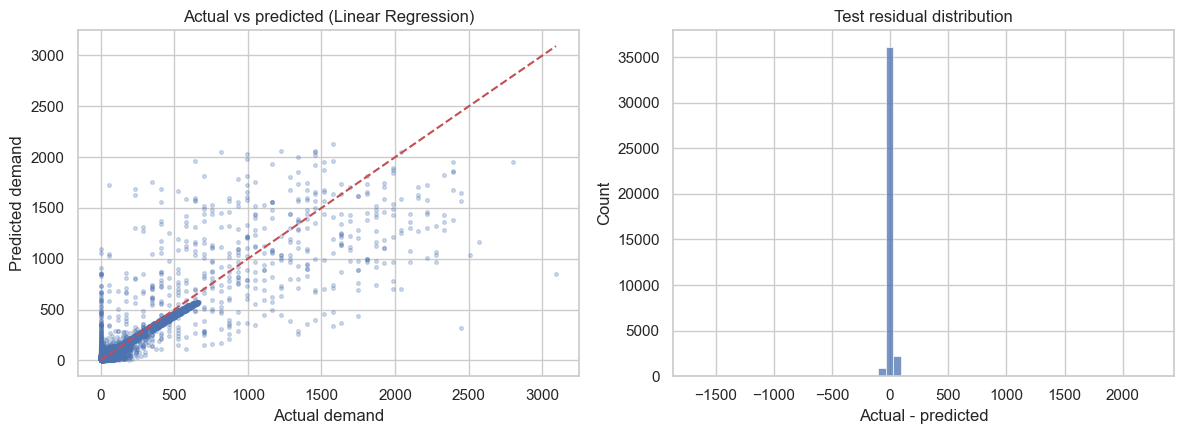

In [9]:
# Required Task 1 model: Linear Regression, refit on train + validation and evaluated once on the untouched test period.
# The naive baselines are the benchmarks it has to be compared with (they are not used to pick the test-time model).
main_regressor = Pipeline([
    ("preprocess", make_preprocessor()),
    ("model", LinearRegression())
])
main_regressor.fit(train_valid[forecast_features], train_valid[target])
y_pred_reg = np.maximum(main_regressor.predict(X_test), 0)
test_regression_metrics = regression_metrics(y_test, y_pred_reg)

comparison_rows = [{"Model": "Linear Regression (required model)", **test_regression_metrics}]
baseline_test_metrics = {}
for name, col in [
    ("Persistence (t-1)", "volume_lag_1"),
    ("Same hour yesterday (t-24)", "volume_lag_24"),
    ("Same hour last week (t-168)", "volume_lag_168")
]:
    p = np.maximum(test[col].to_numpy(), 0)
    baseline_test_metrics[name] = regression_metrics(y_test, p)
    comparison_rows.append({"Model": name, **baseline_test_metrics[name]})

test_forecast_comparison = pd.DataFrame(comparison_rows)
print("Task 1 untouched test metrics (all rows)")
display(test_forecast_comparison.round(4))

pers = baseline_test_metrics["Persistence (t-1)"]
print(f"Linear Regression vs persistence: MSE {test_regression_metrics['MSE'] / pers['MSE'] - 1:+.1%}, "
      f"MAE {test_regression_metrics['MAE'] / pers['MAE'] - 1:+.1%}")

# One very large station can dominate pooled MSE/R2, so also report the metrics without it.
top_station = test.groupby("station_id")[target].mean().idxmax()
keep_rows = (test["station_id"] != top_station).to_numpy()
excl_lin = regression_metrics(y_test.to_numpy()[keep_rows], y_pred_reg[keep_rows])
excl_pers = regression_metrics(y_test.to_numpy()[keep_rows], np.maximum(test["volume_lag_1"].to_numpy()[keep_rows], 0))
print(f"\nExcluding the highest-demand station (id {top_station}):")
display(pd.DataFrame([{"Model": "Linear Regression", **excl_lin},
                      {"Model": "Persistence (t-1)", **excl_pers}]).round(4))

test_forecast_comparison.to_csv(OUTPUT_FOLDER / "task1_test_baseline_comparison.csv", index=False)
pd.DataFrame([{"Model": "Linear Regression", **test_regression_metrics}]).to_csv(
    OUTPUT_FOLDER / "task1_test_metrics.csv", index=False)
validation_results.to_csv(OUTPUT_FOLDER / "task1_validation_model_selection.csv", index=False)

# Error analysis: where is the forecast least reliable?
test_diagnostics = test[["timestamp", "station_id", "hour", "volume"]].copy()
test_diagnostics["prediction"] = y_pred_reg
test_diagnostics["absolute_error"] = np.abs(test_diagnostics["volume"] - test_diagnostics["prediction"])
test_diagnostics["signed_error"] = test_diagnostics["volume"] - test_diagnostics["prediction"]

station_error = (
    test_diagnostics.groupby("station_id")
    .agg(test_MAE=("absolute_error", "mean"),
         mean_actual_demand=("volume", "mean"),
         mean_prediction=("prediction", "mean"),
         observations=("volume", "size"))
    .sort_values("test_MAE", ascending=False)
)
station_error["relative_MAE"] = station_error["test_MAE"] / station_error["mean_actual_demand"].replace(0, np.nan)
hour_error = (
    test_diagnostics.groupby("hour")
    .agg(test_MAE=("absolute_error", "mean"),
         mean_actual_demand=("volume", "mean"))
    .sort_values("test_MAE", ascending=False)
)
display(station_error.head(10).round(3))
display(hour_error.round(3))

station_error.to_csv(OUTPUT_FOLDER / "task1_station_error_analysis.csv")
hour_error.to_csv(OUTPUT_FOLDER / "task1_hour_error_analysis.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, y_pred_reg, s=7, alpha=.25)
max_value = max(float(y_test.max()), float(np.max(y_pred_reg)))
axes[0].plot([0, max_value], [0, max_value], "r--")
axes[0].set(title="Actual vs predicted (Linear Regression)",
            xlabel="Actual demand", ylabel="Predicted demand")
sns.histplot(test_diagnostics["signed_error"], bins=60, ax=axes[1])
axes[1].set(title="Test residual distribution", xlabel="Actual - predicted", ylabel="Count")
fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / "task1_test_diagnostics.png", dpi=150)
plt.show()

## Task 1 interpretation guide

- **Model of record:** Linear Regression, as required. Ridge, Lasso and the naive baselines are comparison points. The validation table shows which candidate had the lowest validation MAE; the test set was not used to choose between them.
- **Benchmark:** the "previous hour" forecast is strong because charging demand changes slowly from hour to hour. A learned model has to beat it to add value. If Linear Regression does not, say so plainly in the report.
- **Pooled metrics:** MSE, RMSE and R2 are dominated by the highest-demand station, so MAE, WAPE, the station-level error table and the "excluding the highest-demand station" table should be read together with them.
- **Post-processing:** predictions are clipped at zero because negative charging demand is not physically meaningful.

# Task 2 - Peak charging-load classification (Logistic Regression)

A station-hour is labelled **peak** when its demand is at or above the 80th percentile of the **training-period** demand. Using only training data avoids leaking validation/test information into the label definition.

In [10]:
# Define peak using a threshold calculated from training targets only.
peak_threshold = float(train[target].quantile(0.80))
print(f"Training-only 80th percentile threshold: {peak_threshold:.6g} reported volume units")

for frame in (train, valid, test, train_valid):
    frame["peak"] = (frame[target] >= peak_threshold).astype(int)

for label, frame in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(f"{label} class proportions:")
    display(frame["peak"].value_counts(normalize=True).sort_index()
            .rename(index={0: "Non-peak", 1: "Peak"}))

# Diagnostics on how the label behaves.
tie_share = float((train[target] == peak_threshold).mean())
print(f"Training peak share: {train['peak'].mean():.2%} (nominal 20%). "
      f"Rows exactly equal to the threshold, which are counted as peak: {tie_share:.2%}. "
      "A peak share above 20% means many station-hours repeat the same capped value.")
peak_by_station = test.groupby("station_id")["peak"].sum().sort_values(ascending=False)
top3 = peak_by_station.head(3)
print(f"The 3 stations with the most test peak rows (stations {list(top3.index)}) contribute "
      f"{top3.sum() / peak_by_station.sum():.1%} of all test peak rows, "
      f"while they are {3 / test['station_id'].nunique():.1%} of the stations. "
      "A much larger share means the global threshold mostly labels large stations rather than unusual hours.")

Training-only 80th percentile threshold: 44 reported volume units
Train class proportions:


peak
Non-peak    0.742472
Peak        0.257528
Name: proportion, dtype: float64

Validation class proportions:


peak
Non-peak    0.749437
Peak        0.250563
Name: proportion, dtype: float64

Test class proportions:


peak
Non-peak    0.701893
Peak        0.298107
Name: proportion, dtype: float64

Training peak share: 25.75% (nominal 20%). Rows exactly equal to the threshold, which are counted as peak: 6.44%. A peak share above 20% means many station-hours repeat the same capped value.
The 3 stations with the most test peak rows (stations ['12', '30', '35']) contribute 16.0% of all test peak rows, while they are 4.8% of the stations. A much larger share means the global threshold mostly labels large stations rather than unusual hours.


In [11]:
# Task 2 model comparison: expanding-window time-series cross-validation.
# All stations at a timestamp stay in the same fold. Preprocessing is fitted
# independently inside each fold through the Pipeline.

from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score, precision_recall_curve

classification_candidates = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", min_samples_leaf=10, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=120, min_samples_leaf=2,
        class_weight="balanced", n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=3,
        min_samples_leaf=10, random_state=42
    ),
    # SVM with probability=True is by far the slowest candidate on ~150k rows;
    # remove this entry for a quick run.
    "SVM (RBF)": SVC(
        kernel="rbf", C=1.0, gamma="scale",
        class_weight="balanced", probability=True,
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=42
    ),
    "SGD Logistic": SGDClassifier(
        loss="log_loss", class_weight="balanced",
        max_iter=2000, tol=1e-3, random_state=42
    )
}

# Split the TRAINING PERIOD by unique timestamps, not individual station rows.
CV_SPLITS = 4
train_unique_times = np.sort(train["timestamp"].unique())
time_cv = TimeSeriesSplit(n_splits=CV_SPLITS)

cv_fold_rows = []
for fold_number, (train_time_idx, valid_time_idx) in enumerate(
    time_cv.split(train_unique_times), start=1
):
    fold_train_times = train_unique_times[train_time_idx]
    fold_valid_times = train_unique_times[valid_time_idx]

    fold_train = train[train["timestamp"].isin(fold_train_times)]
    fold_valid = train[train["timestamp"].isin(fold_valid_times)]

    if fold_train["peak"].nunique() < 2 or fold_valid["peak"].nunique() < 2:
        raise ValueError(
            f"CV fold {fold_number} contains only one class. "
            "Review the chronological split or peak definition."
        )

    print(
        f"Fold {fold_number}: "
        f"train {fold_train.timestamp.min()} to {fold_train.timestamp.max()} "
        f"({len(fold_train):,} rows); "
        f"validation {fold_valid.timestamp.min()} to {fold_valid.timestamp.max()} "
        f"({len(fold_valid):,} rows)"
    )

    for model_name, estimator in classification_candidates.items():
        fold_pipeline = Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", clone(estimator))
        ])
        fold_pipeline.fit(fold_train[forecast_features], fold_train["peak"])

        fold_pred = fold_pipeline.predict(fold_valid[forecast_features])
        fold_prob = fold_pipeline.predict_proba(fold_valid[forecast_features])[:, 1]

        cv_fold_rows.append({
            "Model": model_name,
            "Fold": fold_number,
            "F1": f1_score(fold_valid["peak"], fold_pred, zero_division=0),
            "Precision": precision_score(fold_valid["peak"], fold_pred, zero_division=0),
            "Recall": recall_score(fold_valid["peak"], fold_pred, zero_division=0),
            "PR_AUC": average_precision_score(fold_valid["peak"], fold_prob),
            "ROC_AUC": roc_auc_score(fold_valid["peak"], fold_prob)
        })

classification_cv_folds = pd.DataFrame(cv_fold_rows)
classification_cv_summary = (
    classification_cv_folds.groupby("Model")
    .agg(
        CV_F1_mean=("F1", "mean"), CV_F1_std=("F1", "std"),
        CV_Precision_mean=("Precision", "mean"),
        CV_Recall_mean=("Recall", "mean"),
        CV_PR_AUC_mean=("PR_AUC", "mean"),
        CV_ROC_AUC_mean=("ROC_AUC", "mean")
    )
    .sort_values(["CV_F1_mean", "CV_PR_AUC_mean"], ascending=False)
    .reset_index()
)
display(classification_cv_folds.round(4))
display(classification_cv_summary.round(4))

best_classifier_name = classification_cv_summary.iloc[0]["Model"]
print("Best candidate by training-period expanding-window CV:", best_classifier_name)
print("Required model (problem statement): Logistic Regression")

Fold 1: train 2023-04-08 00:00:00 to 2023-05-02 15:00:00 (37,296 rows); validation 2023-05-02 16:00:00 to 2023-05-27 06:00:00 (37,233 rows)
Fold 2: train 2023-04-08 00:00:00 to 2023-05-27 06:00:00 (74,529 rows); validation 2023-05-27 07:00:00 to 2023-06-20 21:00:00 (37,233 rows)
Fold 3: train 2023-04-08 00:00:00 to 2023-06-20 21:00:00 (111,762 rows); validation 2023-06-20 22:00:00 to 2023-07-15 12:00:00 (37,233 rows)
Fold 4: train 2023-04-08 00:00:00 to 2023-07-15 12:00:00 (148,995 rows); validation 2023-07-15 13:00:00 to 2023-08-09 03:00:00 (37,233 rows)


,Model,Fold,F1,Precision,Recall,PR_AUC,ROC_AUC
0,Dummy (most frequent),1,0.0000,0.0000,0.0000,0.2683,0.5000
1,Logistic Regression,1,0.8690,0.8274,0.9149,0.9321,0.9761
2,Decision Tree,1,0.8583,0.7966,0.9304,0.9025,0.9618
3,Random Forest,1,0.8789,0.8615,0.8971,0.9512,0.9813
4,Extra Trees,1,0.8636,0.8314,0.8984,0.9429,0.9779
5,Gradient Boosting,1,0.8785,0.8724,0.8848,0.9440,0.9767
6,SVM (RBF),1,0.8652,0.8266,0.9077,0.9106,0.9685
7,AdaBoost,1,0.8740,0.8725,0.8756,0.9296,0.9706
8,SGD Logistic,1,0.8583,0.8118,0.9104,0.9252,0.9733
9,Dummy (most frequent),2,0.0000,0.0000,0.0000,0.2804,0.5000


,Model,CV_F1_mean,CV_F1_std,CV_Precision_mean,CV_Recall_mean,CV_PR_AUC_mean,CV_ROC_AUC_mean
0,Gradient Boosting,0.8616,0.0263,0.8509,0.8726,0.9240,0.9719
1,AdaBoost,0.8575,0.0262,0.8524,0.8628,0.9127,0.9675
2,Random Forest,0.8562,0.0267,0.8207,0.8958,0.9232,0.9740
3,SVM (RBF),0.8305,0.0373,0.7623,0.9153,0.8927,0.9640
4,Logistic Regression,0.8262,0.0418,0.7575,0.9120,0.9000,0.9649
5,Extra Trees,0.8229,0.0415,0.7606,0.8998,0.9022,0.9660
6,SGD Logistic,0.8226,0.0373,0.7530,0.9095,0.9000,0.9654
7,Decision Tree,0.8159,0.0464,0.7336,0.9217,0.8657,0.9523
8,Dummy (most frequent),0.0000,0.0000,0.0000,0.0000,0.2584,0.5000


Best candidate by training-period expanding-window CV: Gradient Boosting
Required model (problem statement): Logistic Regression


In [12]:
# Helper used for BOTH the required model (Logistic Regression) and the CV-best model.
#   1. fit on the training period and choose the probability threshold on the validation period;
#   2. refit on train + validation and evaluate the untouched test period once.

def classification_metrics(y_true, pred, prob=None):
    out = {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "PR_AUC": average_precision_score(y_true, prob) if prob is not None else np.nan,
        "ROC_AUC": roc_auc_score(y_true, prob) if (prob is not None and pd.Series(y_true).nunique() == 2) else np.nan
    }
    return out

def fit_and_evaluate_classifier(name):
    estimator = classification_candidates[name]

    validation_pipeline = Pipeline([("preprocess", make_preprocessor()), ("model", clone(estimator))])
    validation_pipeline.fit(train[forecast_features], train["peak"])
    validation_prob = validation_pipeline.predict_proba(valid[forecast_features])[:, 1]

    precision_curve, recall_curve, threshold_values = precision_recall_curve(valid["peak"], validation_prob)
    threshold_f1 = (2 * precision_curve[:-1] * recall_curve[:-1]
                    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12))
    decision_threshold = float(threshold_values[int(np.nanargmax(threshold_f1))]) if len(threshold_values) else 0.50

    threshold_table = pd.DataFrame([
        {"Threshold": thr,
         "Validation_F1": f1_score(valid["peak"], (validation_prob >= thr).astype(int), zero_division=0),
         "Validation_Precision": precision_score(valid["peak"], (validation_prob >= thr).astype(int), zero_division=0),
         "Validation_Recall": recall_score(valid["peak"], (validation_prob >= thr).astype(int), zero_division=0)}
        for thr in (0.50, decision_threshold)
    ])

    final_pipeline = Pipeline([("preprocess", make_preprocessor()), ("model", clone(estimator))])
    final_pipeline.fit(train_valid[forecast_features], train_valid["peak"])
    prob = final_pipeline.predict_proba(X_test)[:, 1]
    pred = (prob >= decision_threshold).astype(int)

    return {"name": name, "pipeline": final_pipeline, "threshold": decision_threshold,
            "threshold_table": threshold_table, "prob": prob, "pred": pred,
            "metrics": classification_metrics(test["peak"], pred, prob)}

lr_result = fit_and_evaluate_classifier("Logistic Regression")
best_result = lr_result if best_classifier_name == "Logistic Regression" else fit_and_evaluate_classifier(best_classifier_name)

for res in {id(r): r for r in (lr_result, best_result)}.values():
    print(f"\n{res['name']}: probability threshold chosen on validation = {res['threshold']:.4f}")
    display(res["threshold_table"].round(4))

# Benchmark: was the station already in peak in the previous hour?
baseline_peak_pred = (test["volume_lag_1"] >= peak_threshold).astype(int)

rows = [
    {"Model": "Baseline: previous hour was peak", **classification_metrics(test["peak"], baseline_peak_pred)},
    {"Model": "Logistic Regression (required model)", "Threshold": lr_result["threshold"], **lr_result["metrics"]},
]
if best_classifier_name != "Logistic Regression":
    rows.append({"Model": f"{best_classifier_name} (best in CV)", "Threshold": best_result["threshold"], **best_result["metrics"]})
task2_test_comparison = pd.DataFrame(rows)
print("\nTask 2 untouched test metrics")
display(task2_test_comparison.round(4))

y_prob_peak, y_pred_peak = best_result["prob"], best_result["pred"]
print(classification_report(test["peak"], lr_result["pred"], labels=[0, 1],
                            target_names=["Non-peak", "Peak"], zero_division=0))
print("Logistic Regression confusion matrix [true rows, predicted columns]:")
print(confusion_matrix(test["peak"], lr_result["pred"], labels=[0, 1]))

classification_cv_folds.to_csv(OUTPUT_FOLDER / "task2_time_series_cv_fold_results.csv", index=False)
classification_cv_summary.to_csv(OUTPUT_FOLDER / "task2_time_series_cv_summary.csv", index=False)
lr_result["threshold_table"].to_csv(OUTPUT_FOLDER / "task2_logistic_validation_threshold_comparison.csv", index=False)
task2_test_comparison.to_csv(OUTPUT_FOLDER / "task2_test_metrics.csv", index=False)


Logistic Regression: probability threshold chosen on validation = 0.6332


,Threshold,Validation_F1,Validation_Precision,Validation_Recall
0,0.5000,0.7937,0.7353,0.8620
1,0.6332,0.8031,0.7826,0.8247



Gradient Boosting: probability threshold chosen on validation = 0.4225


,Threshold,Validation_F1,Validation_Precision,Validation_Recall
0,0.5000,0.8420,0.8293,0.8552
1,0.4225,0.8436,0.8235,0.8648



Task 2 untouched test metrics


,Model,Accuracy,Precision,Recall,F1,PR_AUC,ROC_AUC,Threshold
0,Baseline: previous hour was peak,0.9316,0.8850,0.8854,0.8852,NaN,NaN,NaN
1,Logistic Regression (required model),0.9177,0.8613,0.8627,0.8620,0.9165,0.9696,0.6332
2,Gradient Boosting (best in CV),0.9334,0.8733,0.9083,0.8905,0.9475,0.9776,0.4225


              precision    recall  f1-score   support

    Non-peak       0.94      0.94      0.94     28035
        Peak       0.86      0.86      0.86     11907

    accuracy                           0.92     39942
   macro avg       0.90      0.90      0.90     39942
weighted avg       0.92      0.92      0.92     39942

Logistic Regression confusion matrix [true rows, predicted columns]:
[[26381  1654]
 [ 1635 10272]]


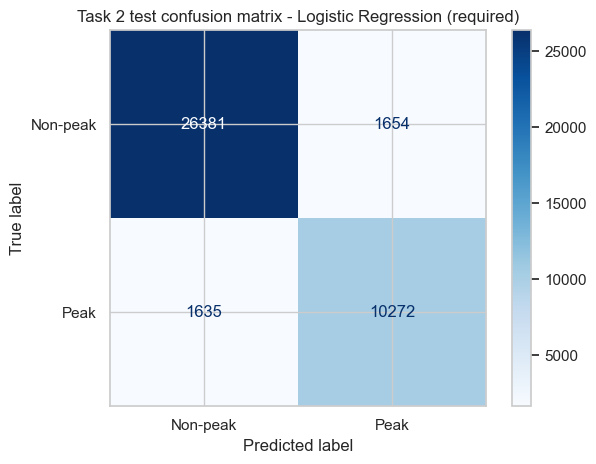

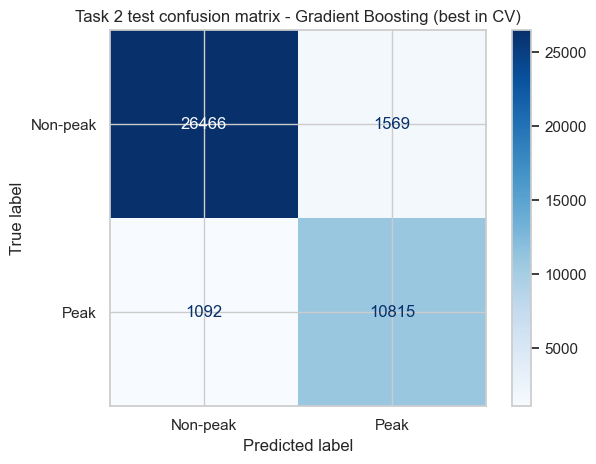

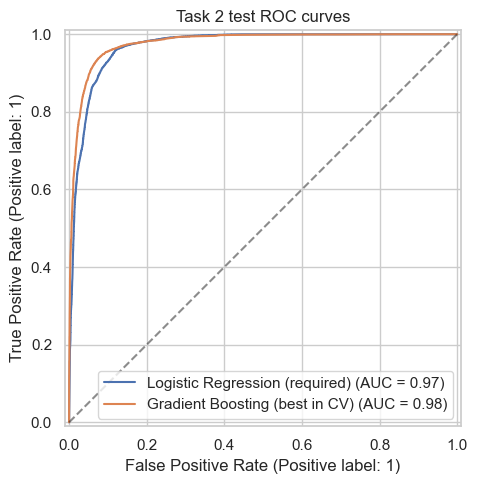

In [13]:
shown = {"Logistic Regression (required)": lr_result}
if best_classifier_name != "Logistic Regression":
    shown[f"{best_classifier_name} (best in CV)"] = best_result

for label, res in shown.items():
    ConfusionMatrixDisplay.from_predictions(
        test["peak"], res["pred"],
        labels=[0, 1], display_labels=["Non-peak", "Peak"],
        cmap="Blues", values_format="d"
    )
    plt.title(f"Task 2 test confusion matrix - {label}")
    plt.tight_layout()
    plt.savefig(OUTPUT_FOLDER / f"task2_confusion_matrix_{res['name'].replace(' ', '_').lower()}.png", dpi=150)
    plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for label, res in shown.items():
    RocCurveDisplay.from_predictions(test["peak"], res["prob"], name=label, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=.5)
ax.set_title("Task 2 test ROC curves")
fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / "task2_roc_curve.png", dpi=150)
plt.show()

### Task 2 model-selection protocol

Nine candidate classifiers are compared with four expanding-window folds inside the training period. Each fold trains on earlier timestamps and validates on a later block; all stations at a timestamp stay together, and preprocessing is fitted separately inside each fold. The best candidate is the one with the highest mean cross-validation F1 (mean PR-AUC breaks ties).

The **required model, Logistic Regression**, is always evaluated on the test period, and so is the CV-best model when it is different. For each of them the probability threshold is chosen on the separate validation period, the model is refit on train + validation, and the test period is evaluated once. The "previous hour was peak" rule is reported as a benchmark because peak status is very persistent.

## Summary and methodological limitations

- Task 1 is a rolling **one-step-ahead** forecast. Actual demand from the previous hour is assumed to become available before the next prediction.
- Same-hour duration, weather and prices are excluded from the forecasting features because their availability at forecast time is not established. `month` and `day_of_month` are excluded because the test period contains a month never seen in training.
- Task 2 uses the same prediction-time-safe features as Task 1 and does not use same-hour duration to infer whether that hour is a peak.
- The peak cutoff is the 80th percentile of training demand. Repeated capped values create ties at the threshold, and one global threshold partly labels large stations. A per-station threshold would measure "unusual for this station" instead.
- Both tasks should be judged against the naive baselines (previous hour, and "previous hour was peak"), not against zero.
- Pooled MSE and R2 are dominated by a few very large stations; read them together with MAE, WAPE and the station-level tables.
- Several stations show smooth or repeated values, which suggests the source data were filled or interpolated; this makes neighbouring hours more similar than raw measurements would be.
- The series covers only six months. Performance may change in other seasons, cities or years.
- The unit of the target is described as reported volume units unless it is confirmed in the dataset documentation.
- This is not a multi-hour-ahead forecast. For 24-hour-ahead operations, features must be built so that no actual demand from the intervening 23 hours is used.

# Task 3 - Clustering of stations with similar behaviour (K-Means)

Hourly records are aggregated to one row per station: average, maximum and variability of demand, average charging duration during active hours, active-hour frequency (a proxy for charging-session frequency), weekend demand and peak-hour frequency (using the training-only peak threshold). K-Means is the required model; DBSCAN and a Gaussian Mixture Model are comparison methods.

These are descriptive full-period aggregates for grouping stations; they are not used to predict anything, so there is no train/test issue here.

In [14]:
cluster_source = model_data.assign(
    is_active=(model_data["volume"] > 0).astype(int),
    is_peak=(model_data["volume"] >= peak_threshold).astype(int),
    weekend_volume=model_data["volume"].where(model_data["is_weekend"] == 1)
)
station_features = cluster_source.groupby("station_id").agg(
    avg_demand=("volume", "mean"),
    max_demand=("volume", "max"),
    demand_std=("volume", "std"),
    total_demand=("volume", "sum"),
    avg_duration=("duration", "mean"),
    active_hour_frequency=("is_active", "mean"),
    weekend_demand=("weekend_volume", "mean"),
    peak_hour_frequency=("is_peak", "mean"),
    longitude=("longitude", "first"),
    latitude=("latitude", "first"),
    total_hours=("volume", "count")
).reset_index()

print("Station-level dataset shape:", station_features.shape)
display(station_features.head())

Station-level dataset shape: (63, 12)


,station_id,avg_demand,max_demand,demand_std,total_demand,avg_duration,active_hour_frequency,weekend_demand,peak_hour_frequency,longitude,latitude,total_hours
0,0,8.334306,70.000000,12.071737,35204.106838,1.189286,0.521070,8.694644,0.024384,145.111076,-37.689403,4224
1,1,30.058160,187.000000,25.987715,126965.666667,1.366280,0.750237,28.764040,0.434422,144.926387,-37.797009,4224
2,10,21.560764,212.666667,23.805911,91072.666667,0.980035,0.590909,23.613834,0.276752,144.920987,-37.723624,4224
3,11,11.350743,80.666667,16.604798,47945.537037,0.515943,0.429924,10.937653,0.118608,145.165947,-37.673700,4224
4,12,42.858432,164.485200,43.362192,181034.015886,2.851409,0.975379,41.452777,0.353693,145.048520,-37.845488,4224


In [15]:
# Average duration only during active charging hours
active_duration = (
    model_data[model_data["volume"] > 0]
    .groupby("station_id")["duration"]
    .mean()
)
station_features["avg_duration_active"] = station_features["station_id"].map(active_duration)

# A station with no demand in the whole period has no behaviour to cluster.
inactive_mask = station_features["avg_demand"] == 0
print("Stations with zero demand over the whole period (excluded from clustering):",
      station_features.loc[inactive_mask, "station_id"].tolist())
constant_mask = (station_features["demand_std"] == 0) & ~inactive_mask
print("Stations with a constant non-zero demand series (kept, but likely a data artefact):",
      station_features.loc[constant_mask, "station_id"].tolist())

cluster_stations = station_features.loc[~inactive_mask].copy().reset_index(drop=True)

clustering_features = [
    "avg_demand",
    "max_demand",
    "demand_std",
    "avg_duration_active",
    "active_hour_frequency",
    "weekend_demand",
    "peak_hour_frequency"
]
X_cluster = cluster_stations[clustering_features].copy()

print("\nClustering feature dataset shape:", X_cluster.shape)
print("Missing values:")
print(X_cluster.isnull().sum())
print("\nFeature statistics:")
display(X_cluster.describe().round(3))

Stations with zero demand over the whole period (excluded from clustering): ['44']
Stations with a constant non-zero demand series (kept, but likely a data artefact): ['3', '35']

Clustering feature dataset shape: (62, 7)
Missing values:
avg_demand               0
max_demand               0
demand_std               0
avg_duration_active      0
active_hour_frequency    0
weekend_demand           0
peak_hour_frequency      0
dtype: int64

Feature statistics:


,avg_demand,max_demand,demand_std,avg_duration_active,active_hour_frequency,weekend_demand,peak_hour_frequency
count,62.000,62.000,62.000,62.000,62.000,62.000,62.000
mean,47.479,263.052,40.039,1.795,0.716,50.465,0.267
std,123.449,661.022,97.841,0.983,0.146,139.505,0.281
min,0.620,2.917,0.000,0.133,0.287,0.577,0.000
25%,8.472,57.141,8.597,1.025,0.626,8.478,0.001
50%,21.780,145.655,19.653,1.807,0.700,20.666,0.194
75%,41.181,227.071,38.168,2.280,0.814,41.090,0.432
max,954.870,5191.667,750.308,4.000,1.000,1084.528,1.000


In [16]:
X_cluster_filled = X_cluster.fillna({"avg_duration_active": 0})

# Right-skewed amounts are log-transformed; frequencies stay on their natural 0-1 scale.
log_features = ["avg_demand", "max_demand", "demand_std", "avg_duration_active", "weekend_demand"]
X_cluster_log = X_cluster_filled.copy()
for col in log_features:
    X_cluster_log[col] = np.log1p(X_cluster_log[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster_log)

print("Scaled feature matrix shape:", X_scaled.shape)
print("Remaining missing values:", np.isnan(X_scaled).sum())
display(pd.DataFrame(X_scaled, columns=clustering_features).describe().round(3))

Scaled feature matrix shape: (62, 7)
Remaining missing values: 0


,avg_demand,max_demand,demand_std,avg_duration_active,active_hour_frequency,weekend_demand,peak_hour_frequency
count,62.000,62.000,62.000,62.000,62.000,62.000,62.000
mean,-0.000,0.000,0.000,-0.000,0.000,0.000,-0.000
std,1.008,1.008,1.008,1.008,1.008,1.008,1.008
min,-2.211,-2.768,-2.334,-2.322,-2.962,-2.204,-0.959
25%,-0.688,-0.568,-0.503,-0.717,-0.620,-0.684,-0.954
50%,0.068,0.187,0.118,0.187,-0.111,0.016,-0.261
75%,0.598,0.547,0.636,0.617,0.674,0.579,0.592
max,3.291,3.097,3.027,1.782,1.961,3.332,2.635


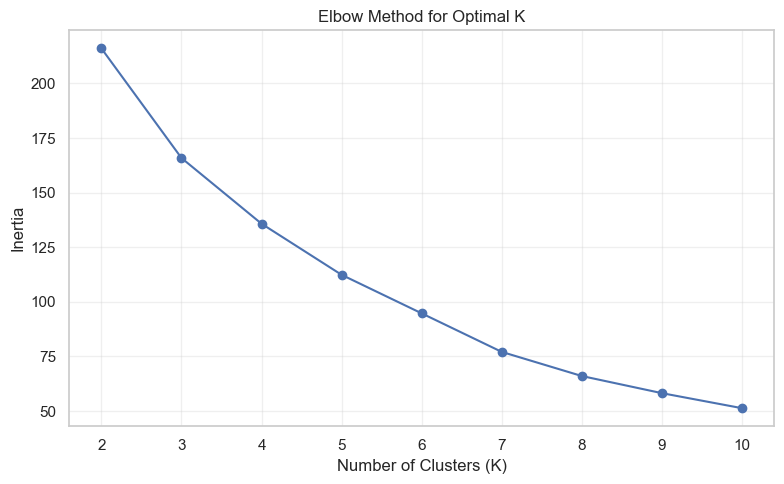

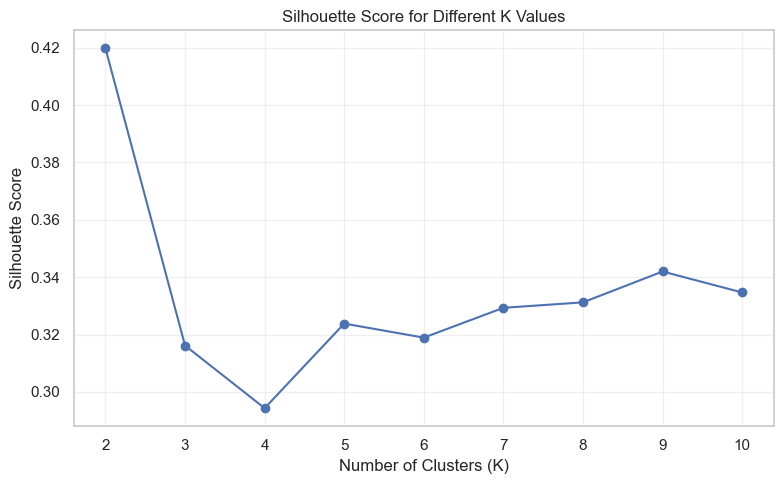

,K,Inertia,Silhouette Score,Smallest cluster
0,2,216.0220,0.4198,30
1,3,165.8460,0.3161,16
2,4,135.7607,0.2943,10
3,5,112.3752,0.3238,6
4,6,94.7358,0.3189,5
5,7,77.0899,0.3293,1
6,8,66.0456,0.3312,1
7,9,58.2044,0.3420,1
8,10,51.3273,0.3347,1


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
inertia_values = []
silhouette_values = []
smallest_cluster_sizes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = kmeans.fit_predict(X_scaled)
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))
    smallest_cluster_sizes.append(int(np.bincount(labels).min()))

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values,
    "Smallest cluster": smallest_cluster_sizes
})
display(k_results.round(4))

In [18]:
# K is chosen by the highest silhouette score among values that leave no tiny cluster
# (silhouette alone tends to reward isolating one or two extreme stations as their own clusters).
# A K=4 view is also shown because a small K mostly separates low-demand from high-demand stations.
MIN_CLUSTER_SIZE = 3
eligible_k = k_results[k_results["Smallest cluster"] >= MIN_CLUSTER_SIZE]
k_pool = eligible_k if len(eligible_k) else k_results
best_k = int(k_pool.loc[k_pool["Silhouette Score"].idxmax(), "K"])
detail_k = 4
print(f"K chosen by silhouette among values with every cluster >= {MIN_CLUSTER_SIZE} stations:", best_k)

kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=20)
cluster_stations["cluster"] = kmeans_model.fit_predict(X_scaled)

print("Cluster distribution:")
print(cluster_stations["cluster"].value_counts().sort_index())

cluster_profile = cluster_stations.groupby("cluster")[clustering_features].mean().round(2)
print("\nCluster profiles (K =", best_k, "):")
display(cluster_profile)

kmeans_detail = KMeans(n_clusters=detail_k, random_state=42, n_init=20)
cluster_stations["cluster_k4"] = kmeans_detail.fit_predict(X_scaled)
cluster_profile_k4 = cluster_stations.groupby("cluster_k4")[clustering_features].mean().round(2)
cluster_profile_k4["stations"] = cluster_stations["cluster_k4"].value_counts().sort_index()
print(f"\nDetailed view (K = {detail_k}), silhouette = "
      f"{k_results.loc[k_results['K'] == detail_k, 'Silhouette Score'].iloc[0]:.4f}:")
display(cluster_profile_k4)

print("\nStation cluster assignments:")
display(cluster_stations[["station_id", "cluster", "cluster_k4"]].sort_values("cluster"))

K chosen by silhouette among values with every cluster >= 3 stations: 2
Cluster distribution:
cluster
0    32
1    30
Name: count, dtype: int64

Cluster profiles (K = 2 ):


,avg_demand,max_demand,demand_std,avg_duration_active,active_hour_frequency,weekend_demand,peak_hour_frequency
cluster,,,,,,,
0,9.53,60.25,9.17,1.15,0.69,9.63,0.04
1,87.96,479.38,72.97,2.49,0.74,94.02,0.51



Detailed view (K = 4), silhouette = 0.2943:


,avg_demand,max_demand,demand_std,avg_duration_active,active_hour_frequency,weekend_demand,peak_hour_frequency,stations
cluster_k4,,,,,,,,
0,34.53,247.28,37.58,2.17,0.71,34.67,0.38,22
1,5.89,21.48,2.84,0.62,0.76,5.97,0.00,12
2,191.70,914.38,140.33,3.05,0.83,209.50,0.75,10
3,10.91,81.53,12.13,1.42,0.63,11.08,0.04,18



Station cluster assignments:


,station_id,cluster,cluster_k4
0,0,0,3
3,11,0,3
10,18,0,1
9,17,0,3
12,2,0,1
...,...,...,...
53,58,1,0
56,60,1,2
59,7,1,2
60,8,1,0


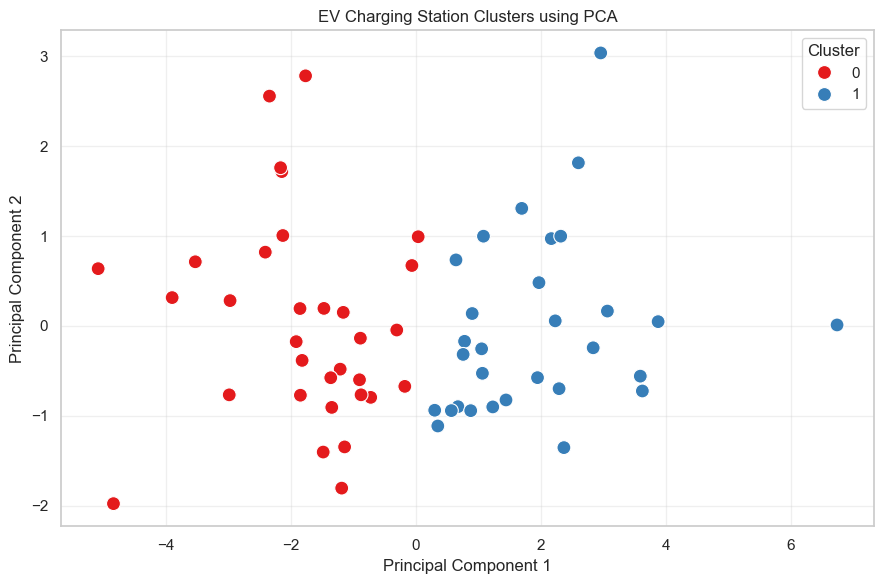

Explained variance by PC1 and PC2: 89.5 %


In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_stations["cluster"].values,
    "Station": cluster_stations["station_id"].values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=100)
plt.title("EV Charging Station Clusters using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "task3_kmeans_pca_clusters.png", dpi=150)
plt.show()

print("Explained variance by PC1 and PC2:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

In [20]:
from sklearn.cluster import DBSCAN

eps_values = [0.8, 1.0, 1.2, 1.5, 2.0, 2.5]
min_samples_values = [3, 4, 5]

dbscan_results = []
for eps in eps_values:
    for min_samples in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels) - {-1})
        n_noise = int(np.sum(labels == -1))
        non_noise_mask = labels != -1
        if n_clusters >= 2 and len(set(labels[non_noise_mask])) >= 2:
            score = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
        else:
            score = np.nan
        dbscan_results.append({"eps": eps, "min_samples": min_samples, "Clusters": n_clusters,
                               "Noise Points": n_noise, "Silhouette Score": score})

dbscan_results_df = pd.DataFrame(dbscan_results)
display(dbscan_results_df.round(4))

,eps,min_samples,Clusters,Noise Points,Silhouette Score
0,0.8,3,3,25,0.3360
1,0.8,4,2,29,0.3132
2,0.8,5,3,35,0.5030
3,1.0,3,1,16,NaN
4,1.0,4,1,20,NaN
5,1.0,5,1,23,NaN
6,1.2,3,1,12,NaN
7,1.2,4,1,13,NaN
8,1.2,5,2,15,0.3392
9,1.5,3,1,5,NaN


In [21]:
# Choose the DBSCAN setting with the best silhouette among settings that find at least 2 clusters
# and leave at most 40% of stations as noise.
eligible = dbscan_results_df.dropna(subset=["Silhouette Score"])
eligible = eligible[eligible["Noise Points"] <= 0.4 * len(X_scaled)]
if len(eligible):
    best_db = eligible.sort_values("Silhouette Score", ascending=False).iloc[0]
    db_eps, db_min_samples = float(best_db["eps"]), int(best_db["min_samples"])
else:
    db_eps, db_min_samples = 0.8, 3
print("DBSCAN setting used: eps =", db_eps, ", min_samples =", db_min_samples)

cluster_stations["dbscan_cluster"] = DBSCAN(eps=db_eps, min_samples=db_min_samples).fit_predict(X_scaled)

print("\nDBSCAN Cluster Distribution (-1 = noise):")
print(cluster_stations["dbscan_cluster"].value_counts().sort_index())

dbscan_profiles = (
    cluster_stations[cluster_stations["dbscan_cluster"] != -1]
    .groupby("dbscan_cluster")[clustering_features].mean().round(2)
)
print("\nDBSCAN Cluster Profiles:")
display(dbscan_profiles)

noise_stations = cluster_stations[cluster_stations["dbscan_cluster"] == -1]
print("\nNumber of noise stations:", len(noise_stations))
display(noise_stations[["station_id"] + clustering_features].round(3))

DBSCAN setting used: eps = 1.2 , min_samples = 5

DBSCAN Cluster Distribution (-1 = noise):
dbscan_cluster
-1    15
 0    43
 1     4
Name: count, dtype: int64

DBSCAN Cluster Profiles:


,avg_demand,max_demand,demand_std,avg_duration_active,active_hour_frequency,weekend_demand,peak_hour_frequency
dbscan_cluster,,,,,,,
0,26.68,192.76,26.82,1.87,0.68,27.39,0.25
1,2.62,18.20,2.90,0.62,0.66,2.73,0.00



Number of noise stations: 15


,station_id,avg_demand,max_demand,demand_std,avg_duration_active,active_hour_frequency,weekend_demand,peak_hour_frequency
4,12,42.858,164.485,43.362,2.923,0.975,41.453,0.354
6,14,59.907,170.500,23.796,2.805,0.971,62.120,0.940
23,3,22.000,22.000,0.000,1.000,1.000,22.000,0.000
24,30,156.046,665.729,205.745,2.796,0.698,164.300,0.567
28,34,954.870,5191.667,750.308,3.162,0.863,1084.528,0.863
29,35,200.000,200.000,0.000,4.000,1.000,200.000,1.000
31,37,11.370,16.407,1.394,0.517,1.000,11.424,0.000
36,41,0.620,2.917,0.613,0.133,0.669,0.577,0.000
41,47,8.048,41.556,5.275,0.391,0.936,7.611,0.000
42,48,5.994,35.000,6.215,0.596,0.958,6.090,0.000


,K,Silhouette Score,BIC,AIC
0,2,0.4165,647.4542,496.4276
1,3,0.3000,488.8381,261.2348
2,4,0.2543,419.8403,115.6601
3,5,0.3093,362.8923,-17.8648
4,6,0.3213,391.4632,-65.8707
5,7,0.3141,293.9087,-240.0020
6,8,0.2759,314.3638,-296.1238
7,9,0.2762,366.6375,-320.4269
8,10,0.3222,197.3356,-566.3057


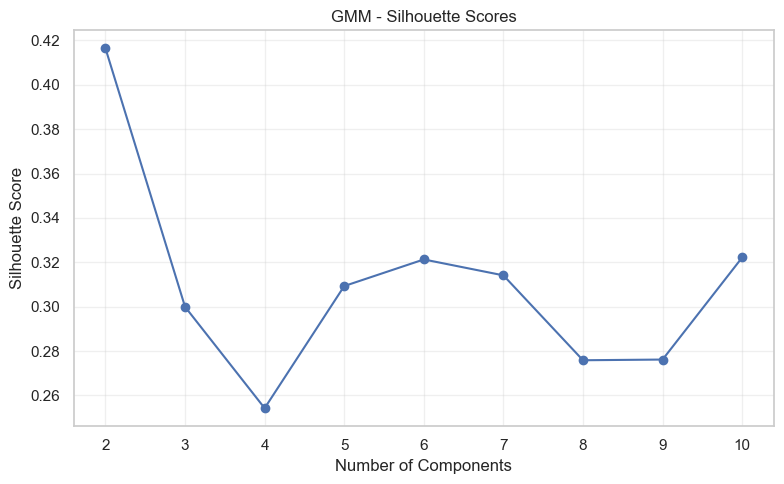

In [22]:
from sklearn.mixture import GaussianMixture

gmm_results = []
for k in range(2, 11):
    gmm = GaussianMixture(n_components=k, covariance_type="full", random_state=42, n_init=5)
    labels = gmm.fit_predict(X_scaled)
    gmm_results.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "BIC": gmm.bic(X_scaled),
        "AIC": gmm.aic(X_scaled)
    })
gmm_results_df = pd.DataFrame(gmm_results)
display(gmm_results_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(gmm_results_df["K"], gmm_results_df["Silhouette Score"], marker="o")
plt.xlabel("Number of Components")
plt.ylabel("Silhouette Score")
plt.title("GMM - Silhouette Scores")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
gmm_model = GaussianMixture(n_components=best_k, covariance_type="full", random_state=42, n_init=5)
gmm_labels = gmm_model.fit_predict(X_scaled)
cluster_stations["gmm_cluster"] = gmm_labels
cluster_stations["gmm_confidence"] = gmm_model.predict_proba(X_scaled).max(axis=1)

print("GMM Cluster Distribution:")
print(cluster_stations["gmm_cluster"].value_counts().sort_index())

gmm_profiles = cluster_stations.groupby("gmm_cluster")[clustering_features].mean().round(2)
print("\nGMM Cluster Profiles:")
display(gmm_profiles)

GMM Cluster Distribution:
gmm_cluster
0    30
1    32
Name: count, dtype: int64

GMM Cluster Profiles:


,avg_demand,max_demand,demand_std,avg_duration_active,active_hour_frequency,weekend_demand,peak_hour_frequency
gmm_cluster,,,,,,,
0,9.01,57.52,8.31,1.10,0.69,9.09,0.03
1,83.55,455.74,69.78,2.45,0.74,89.25,0.49


In [24]:
final_station_results = cluster_stations[
    ["station_id", "cluster", "cluster_k4", "dbscan_cluster", "gmm_cluster", "gmm_confidence"]
].copy()
final_station_results.to_csv(OUTPUT_FOLDER / "task3_station_cluster_assignments.csv", index=False)
cluster_profile.to_csv(OUTPUT_FOLDER / "task3_kmeans_cluster_profiles.csv")
cluster_profile_k4.to_csv(OUTPUT_FOLDER / "task3_kmeans_k4_cluster_profiles.csv")
gmm_profiles.to_csv(OUTPUT_FOLDER / "task3_gmm_cluster_profiles.csv")
print("Task 3 clustering results saved successfully.")

Task 3 clustering results saved successfully.


In [25]:
km_silhouette = float(k_results.loc[k_results["K"] == best_k, "Silhouette Score"].iloc[0])
gmm_silhouette = float(silhouette_score(X_scaled, cluster_stations["gmm_cluster"])) if cluster_stations["gmm_cluster"].nunique() > 1 else float("nan")
n_db_clusters = len(set(cluster_stations["dbscan_cluster"]) - {-1})
n_db_noise = int((cluster_stations["dbscan_cluster"] == -1).sum())
n_clustered = len(cluster_stations)
n_excluded = len(station_features) - n_clustered
detail_sentence = "" if best_k == detail_k else f" The K = {detail_k} view gives a finer split (see the profile table)."

display(Markdown(f"""
### Task 3 results

- **Data:** {n_clustered} stations with {len(clustering_features)} behaviour features ({n_excluded} zero-demand station(s) excluded). Skewed amounts were log-transformed and all features standardised.
- **K-Means (required model):** best silhouette at K = {best_k} (silhouette {km_silhouette:.4f}, smallest cluster has at least {MIN_CLUSTER_SIZE} stations).{detail_sentence}
- **GMM (comparison):** {best_k} components, silhouette {gmm_silhouette:.4f}.
- **DBSCAN (comparison):** eps = {db_eps}, min_samples = {db_min_samples} gave {n_db_clusters} cluster(s) and {n_db_noise} noise station(s) ({n_db_noise / n_clustered:.0%} of stations).
- **Interpretation:** read the cluster-profile tables above. The groups mainly separate stations by overall demand level (average, maximum and variability move together), with active-hour and peak-hour frequency adding the behavioural difference. Stations with a constant non-zero series look like data artefacts rather than usage patterns.
"""))


### Task 3 results

- **Data:** 62 stations with 7 behaviour features (1 zero-demand station(s) excluded). Skewed amounts were log-transformed and all features standardised.
- **K-Means (required model):** best silhouette at K = 2 (silhouette 0.4198, smallest cluster has at least 3 stations). The K = 4 view gives a finer split (see the profile table).
- **GMM (comparison):** 2 components, silhouette 0.4165.
- **DBSCAN (comparison):** eps = 1.2, min_samples = 5 gave 2 cluster(s) and 15 noise station(s) (24% of stations).
- **Interpretation:** read the cluster-profile tables above. The groups mainly separate stations by overall demand level (average, maximum and variability move together), with active-hour and peak-hour frequency adding the behavioural difference. Stations with a constant non-zero series look like data artefacts rather than usage patterns.


# Task 4 - Charging-duration forecasting 

Uses only past duration and volume lags, calendar fields and stable station metadata. Candidates are compared on validation MAE, the chosen model is refit on train + validation, and only that model is evaluated on the untouched test period.

Duration train: 2023-04-08 00:00:00 to 2023-08-09 03:00:00
Duration validation: 2023-08-09 04:00:00 to 2023-09-04 13:00:00
Duration test: 2023-09-04 14:00:00 to 2023-09-30 23:00:00


,Model,Validation_MAE,R2
0,Extra Trees,0.450024,0.753075
1,Random Forest,0.451562,0.745146
2,Decision Tree,0.460579,0.732829
3,Hist Gradient Boosting,0.461950,0.754347
4,Lasso (alpha=0.001),0.467530,0.741221
5,Ridge (alpha=10),0.472164,0.741685
6,Linear Regression,0.472184,0.741678


Selected using validation MAE only: Extra Trees
Selected duration model: Extra Trees
Task 4 untouched test results: {'MAE': 0.34532495450895445, 'MSE': 0.3698072435969569, 'RMSE': 0.6081177876011825, 'R2': 0.9127283461369371}


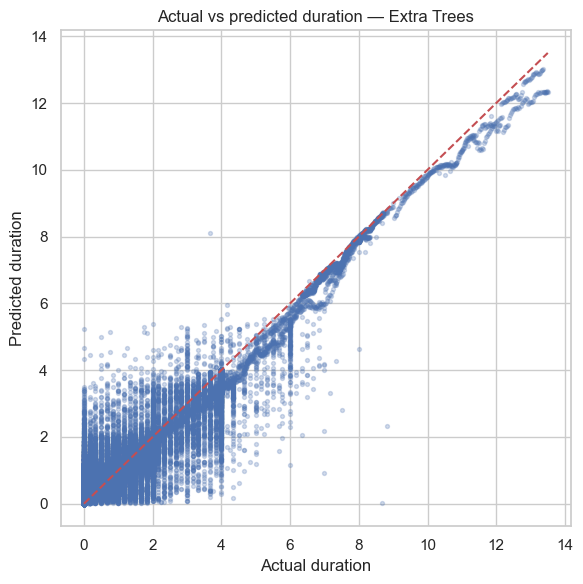

In [29]:
from sklearn.linear_model import Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

duration_data = long_data.copy()
duration_data = duration_data.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

for lag in [1, 24, 168]:
    duration_data[f"duration_lag_{lag}"] = (
        duration_data.groupby("station_id")["duration"].shift(lag)
    )
    duration_data[f"volume_lag_{lag}"] = (
        duration_data.groupby("station_id")["volume"].shift(lag)
    )

duration_features = [
    "duration_lag_1", "duration_lag_24", "duration_lag_168",
    "volume_lag_1", "volume_lag_24", "volume_lag_168",
    "hour", "day_of_week", "is_weekend",
    "station_id", "longitude", "latitude", "pile_num", "perimeter", "area"
]
duration_features = [c for c in duration_features if c in duration_data.columns]

for col in duration_features + ["duration"]:
    if col != "station_id":
        duration_data[col] = pd.to_numeric(duration_data[col], errors="coerce")

duration_data = duration_data.dropna(subset=[
    "duration", "duration_lag_1", "duration_lag_24", "duration_lag_168",
    "volume_lag_1", "volume_lag_24", "volume_lag_168"
]).copy()

duration_times = np.sort(duration_data["timestamp"].unique())
d_train_end = int(len(duration_times) * 0.70)
d_valid_end = int(len(duration_times) * 0.85)
d_train_times = duration_times[:d_train_end]
d_valid_times = duration_times[d_train_end:d_valid_end]
d_test_times = duration_times[d_valid_end:]

train_duration = duration_data[duration_data.timestamp.isin(d_train_times)].copy()
valid_duration = duration_data[duration_data.timestamp.isin(d_valid_times)].copy()
test_duration = duration_data[duration_data.timestamp.isin(d_test_times)].copy()

print("Duration train:", train_duration.timestamp.min(), "to", train_duration.timestamp.max())
print("Duration validation:", valid_duration.timestamp.min(), "to", valid_duration.timestamp.max())
print("Duration test:", test_duration.timestamp.min(), "to", test_duration.timestamp.max())

duration_cat = [
    c for c in duration_features
    if not pd.api.types.is_numeric_dtype(train_duration[c].dtype)
]
duration_num = [c for c in duration_features if c not in duration_cat]

duration_transformers = []
if duration_num:
    duration_transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]),
        duration_num
    ))
if duration_cat:
    duration_transformers.append((
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        duration_cat
    ))
duration_preprocessor = ColumnTransformer(duration_transformers, remainder="drop", sparse_threshold=0)
X_train_d = train_duration[duration_features]
y_train_d = train_duration["duration"]
X_valid_d = valid_duration[duration_features]
y_valid_d = valid_duration["duration"]
X_test_d = test_duration[duration_features]
y_test_d = test_duration["duration"]


duration_candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=10.0),
    "Lasso (alpha=0.001)": Lasso(alpha=0.001, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=20, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150, max_depth=20, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40, random_state=42),
}

duration_validation_rows = []
for name, estimator in duration_candidates.items():
    pipeline = Pipeline([
        ("preprocess", clone(duration_preprocessor)),
        ("model", clone(estimator))
    ])
    pipeline.fit(X_train_d, y_train_d)
    prediction = pipeline.predict(X_valid_d)
    duration_validation_rows.append({
        "Model": name,
        "Validation_MAE": mean_absolute_error(y_valid_d, prediction),
        "R2": r2_score(y_valid_d, prediction)
    })

duration_validation_results = (
    pd.DataFrame(duration_validation_rows)
    .sort_values("Validation_MAE")
    .reset_index(drop=True)
)
display(duration_validation_results)
best_duration_name = duration_validation_results.iloc[0]["Model"]
print("Selected using validation MAE only:", best_duration_name)

# Final fit and one evaluation on the untouched test set.
train_valid_duration = pd.concat(
    [train_duration, valid_duration], ignore_index=True
)
final_duration_model = Pipeline([
    ("preprocess", clone(duration_preprocessor)),
    ("model", clone(duration_candidates[best_duration_name]))
])
final_duration_model.fit(
    train_valid_duration[duration_features],
    train_valid_duration["duration"]
)
duration_prediction = final_duration_model.predict(X_test_d)

duration_results = {
    "MAE": mean_absolute_error(y_test_d, duration_prediction),
    "MSE": mean_squared_error(y_test_d, duration_prediction),
    "RMSE": mean_squared_error(y_test_d, duration_prediction) ** 0.5,
    "R2": r2_score(y_test_d, duration_prediction)
}
print("Selected duration model:", best_duration_name)
print("Task 4 untouched test results:", duration_results)

duration_validation_results.to_csv(
    OUTPUT_FOLDER / "task4_duration_validation_results.csv", index=False
)
pd.DataFrame([{"Model": best_duration_name, **duration_results}]).to_csv(
    OUTPUT_FOLDER / "task4_duration_test_metrics.csv", index=False
)

plt.figure(figsize=(6, 6))
plt.scatter(y_test_d, duration_prediction, alpha=0.25, s=8)
plot_limit = max(float(y_test_d.max()), float(np.max(duration_prediction)))
plt.plot([0, plot_limit], [0, plot_limit], "r--")
plt.title(f"Actual vs predicted duration — {best_duration_name}")
plt.xlabel("Actual duration")
plt.ylabel("Predicted duration")
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER / "task4_duration_test_diagnostics.png", dpi=150)
plt.show()

In [30]:
duration_baselines = []
for name, col in [("Previous hour (t-1)", "duration_lag_1"),
                  ("Same hour yesterday (t-24)", "duration_lag_24"),
                  ("Same hour last week (t-168)", "duration_lag_168")]:
    p = np.maximum(test_duration[col].to_numpy(), 0)
    duration_baselines.append({"Model": name,
                               "MAE": mean_absolute_error(y_test_d, p),
                               "RMSE": mean_squared_error(y_test_d, p) ** 0.5,
                               "R2": r2_score(y_test_d, p)})
duration_baselines.append({"Model": f"{best_duration_name} (selected)", **duration_results})
display(pd.DataFrame(duration_baselines).round(4))

,Model,MAE,RMSE,R2,MSE
0,Previous hour (t-1),0.2895,0.6803,0.8908,NaN
1,Same hour yesterday (t-24),0.6013,1.0968,0.7161,NaN
2,Same hour last week (t-168),0.8691,1.4672,0.4920,NaN
3,Extra Trees (selected),0.3453,0.6081,0.9127,0.3698
